In [1]:
## Notebook based on ipynb available within the RDKit AutomatedSeriesClassification repository [https://github.com/rdkit/AutomatedSeriesClassification]

## First clone the GitHub repository and install the package. From there you will also need to set up the relevant chembl file. 
## Instructions for both are available in the AutomatedSeriesClassification README

## All raw potency datasets are available at the cited data sources, define in the README and manuscript

In [ ]:
import imp
import pickle
import os
import sys
import time

import pandas as pd
import numpy as np
import sklearn
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import SVG
from matplotlib import rcParams
from matplotlib.colors import hex2color
from rdkit import Chem, rdBase
from rdkit.Chem import rdFMCS, Draw, PandasTools, AllChem, DataStructs, Descriptors
from rdkit.Chem import rdSubstructLibrary
from rdkit.Chem.Draw import IPythonConsole
from rdkit import DataStructs
from rdkit.Chem import rdmolops


print('RDKit version: ',rdBase.rdkitVersion)
print('Pandas version:', pd.__version__)
print('Numpy version:', np.__version__)
print('MatplotLib version:', mpl.__version__)
print('Sklearn version:', sklearn.__version__)
print('Seaborn version:', sns.__version__)



In [3]:
from utils import buildFilterCatalog, assignFilters

In [4]:
import automated_series_classification
imp.reload(automated_series_classification)
from automated_series_classification import utilsDataPrep
from automated_series_classification import mainSeriesClassification
imp.reload(mainSeriesClassification)
from automated_series_classification import utilsDrawing
from automated_series_classification import UPGMAclustering
imp.reload(UPGMAclustering)


<module 'automated_series_classification.UPGMAclustering' from '/da/CADD/torrepak/ExploreMOOs/ScaffoldDefinition/AutomatedSeriesClassification/src/automated_series_classification/UPGMAclustering.py'>

In [ ]:
project_settings = {"Renin": {"project_name": "Renin", "dbpath": "./rdk_db/renin_db.pkl"},
                    "ALDH1A1": {"project_name": "ALDH1A1", "dbpath": "./rdk_db/aldh1a1_db.pkl"},
                    "PDE10A": {"project_name": "PDE10A", "dbpath": "./rdk_db/pde10a_db.pkl"},
                    "FXA": {"project_name": "FXA", "dbpath": "./rdk_db/fxa_db.pkl"},
                    "MMP38": {"project_name": "MMP38", "dbpath": "./rdk_db/mmp38_db.pkl"},
                    "PPARd": {"project_name": "PPARd", "dbpath": "./rdk_db/ppard_db.pkl"},
                    }

## Define variables

In [ ]:

project = "Renin" # Select which project to work on

filename = "" # filename for raw potency data
datapath="" # file path for raw potency data

smiles_col = "Smiles" # set name of smiles column in raw potency data

scaffold_folder_path = "./scaffolds" # folder path in which to store defined scaffolds - ensure a unique folder for each project

pkl_path = "./chembl33_sssdata.pkl"

Load ChEMBL database for substructure matching (constructed during data preprocessing)

In [6]:
%%time
with open(pkl_path,'rb') as file:
    chembl_library = pickle.load(file)
    

CPU times: user 9.54 s, sys: 1.18 s, total: 10.7 s
Wall time: 10.8 s


In [7]:
Nchembl = len(chembl_library)

In [10]:
flimit=1e-4
MinClusterSize=5
onlyCompleteRings=False
proj=project_settings[project]["project_name"]
dbpath=project_settings[project]['dbpath']
filename=filename
datapath=datapath

### UPGMA classification

In [11]:
UPGMAClassification=mainSeriesClassification.Classification(proj, datapath, dbpath, filename, chembl_library, 
                                                            flimit, MinClusterSize, clustering='UPGMA',  smilesCol=smiles_col, 
                                                            calcDists=True, calcScores=False, useArthor=False, onlyCompleteRings = onlyCompleteRings)

read 396 molecules


In [12]:
start=time.time()
UPGMAClassification.ApplyClustering()
end=time.time()
print(f"Time elapsed during the calculation: {end-start:.1f}")

Time elapsed during the calculation: 37.2


In [13]:
len(UPGMAClassification.MCSdict)

6

In [14]:
mcs_keys = []
n_cpds = []
for mcs_key, res in UPGMAClassification.MCSdict.items():
    mcs_keys.append(Chem.MolFromSmarts(res[2]))
    n_cpds.extend(res[-1])
    

In [15]:
len(set(n_cpds))

396

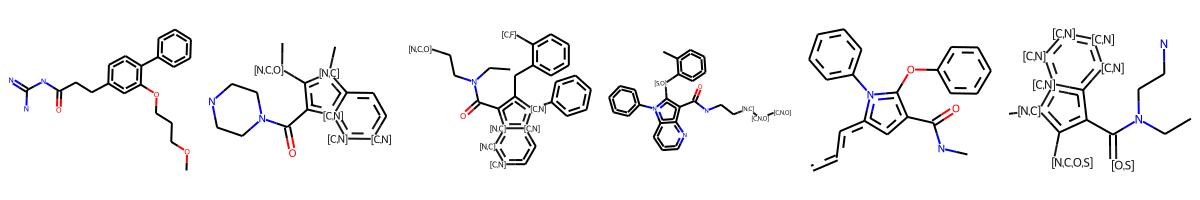

In [16]:
Draw.MolsToImage(mcs_keys, molsPerRow=5)


In [17]:
mol_data = UPGMAClassification.moldata_proj

In [18]:
MCS_all = []
for clst_id, clst_df in mol_data.explode("ClusterID").groupby("ClusterID"):
    mollist = [Chem.MolFromSmiles(s) for s in clst_df["Smiles"]]
    MCS=rdFMCS.FindMCS(mollist,atomCompare=rdFMCS.AtomCompare.CompareElements,bondCompare=rdFMCS.BondCompare.CompareOrderExact,ringMatchesRingOnly=True,completeRingsOnly=True, threshold= 0.8, timeout=1)
    MCS_all.append(MCS)


In [19]:
scaffold_smarts = {}
for clst_id, clst_df in mol_data.explode("ClusterID").groupby("ClusterID"):
    if len(clst_df) == 1:
        mol_data.loc[clst_df.index] = None
        continue
    smis = [Chem.MolFromSmiles(s) for s in clst_df["Smiles"]]
    mcs=rdFMCS.FindMCS(smis,atomCompare=rdFMCS.AtomCompare.CompareElements,bondCompare=rdFMCS.BondCompare.CompareOrderExact,ringMatchesRingOnly=True,completeRingsOnly=True, threshold= 0.8, timeout=2)
    if mcs.smartsString is not None:
        scaffold_smarts[clst_id] = mcs.smartsString
    

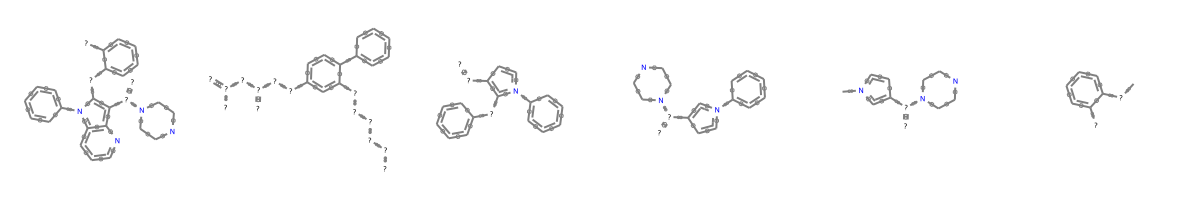

In [20]:
Draw.MolsToGridImage([Chem.MolFromSmarts(s) for s in scaffold_smarts.values()], molsPerRow=min(10, len(scaffold_smarts)))

In [21]:
mol_data_exp = mol_data.explode("ClusterID")

catalog = buildFilterCatalog()

dummy_atom = Chem.MolFromSmiles("*")
hydrogen_atom = Chem.MolFromSmiles('[H]')
carbon_atom = Chem.MolFromSmiles('[C]')

rm_scaffold = []

for clst, smarts in scaffold_smarts.items():
    md = mol_data_exp[mol_data_exp["ClusterID"] == clst]
    smi = md["Smiles"].tolist()
    nibr_filt = [assignFilters(catalog, mol)[-1] for mol in smi]
    if sum(nibr_filt) == len(smi)*10:
        rm_scaffold.append(clst)



In [24]:
from collections import Counter

In [25]:
catalog = buildFilterCatalog()

dummy_atom = Chem.MolFromSmiles("*")
hydrogen_atom = Chem.MolFromSmiles('[H]')
carbon_atom = Chem.MolFromSmiles('C')

scaffold_structure = {}
for clst, smarts in scaffold_smarts.items():
    md = mol_data_exp[mol_data_exp["ClusterID"] == clst]
    smi = md["Smiles"].tolist()
    smarts = Chem.MolFromSmarts(smarts)
    pot_scf = []
    for s in smi:
        scf = rdmolops.ReplaceSidechains(Chem.MolFromSmiles(s), smarts)
        if scf is None: continue
        rdmolops.Cleanup(scf)
        pot_scf.append(Chem.MolToSmiles(scf))
    # scaffs = [Chem.MolToSmiles(rdmolops.Cleanup(rdmolops.ReplaceSidechains(Chem.MolFromSmiles(s), smarts))) for s in smi]
    for scf, _ in Counter(pot_scf).most_common(len(pot_scf)):
        if scf.count("*") > 4: continue
        if scf.count("*") == 0: continue
        if Chem.MolFromSmiles(scf) is not None:
            if Chem.MolFromSmiles(scf).GetNumHeavyAtoms() >= 7:
                scaffold_structure[clst] = scf
                break
    # print(Counter(pot_scf))

[17:10:19] WARNING: not removing hydrogen atom without neighbors
[17:10:20] non-ring atom 7 marked aromatic
[17:10:20] non-ring atom 9 marked aromatic
[17:10:20] non-ring atom 1 marked aromatic
[17:10:20] non-ring atom 8 marked aromatic
[17:10:20] non-ring atom 7 marked aromatic


In [26]:
len(mol_data_exp[mol_data_exp["ClusterID"].isin(scaffold_structure.keys())]["Smiles"].unique())

353

In [27]:
len(mol_data_exp[mol_data_exp["ClusterID"].isin(scaffold_structure.keys())]["Smiles"].unique())/len(mol_data)

0.8914141414141414

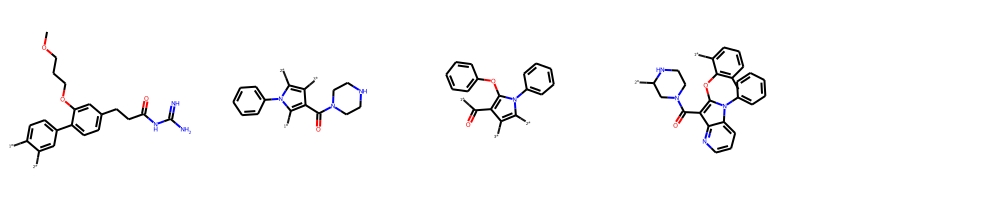

In [28]:
Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in set(scaffold_structure.values())], molsPerRow=5)

In [ ]:
i = 1
for scf in set(scaffold_structure.values()):

    with open(os.path.join(scaffold_folder_path, f"scaffolds_{i}.smi"), "w") as f:
        scf = Chem.MolFromSmiles(scf)
        Chem.RemoveStereochemistry(scf) 
        f.write(Chem.MolToSmiles(scf))
    i += 1